In [ ]:
import torch
import torchmetrics
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from torchmetrics.classification import MulticlassConfusionMatrix, MulticlassPrecisionRecallCurve
from torchmetrics.regression import R2Score, MeanSquaredError
from sklearn.datasets import load_digits, fetch_california_housing
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from torch.utils.data import DataLoader, Dataset, TensorDataset

In [ ]:
X, y = load_digits(return_X_y=True)
X = torch.FloatTensor(X)
y = torch.LongTensor(y)
data = TensorDataset(X, y)
loader = DataLoader(data, batch_size=16, shuffle=True, drop_last=False)

In [ ]:
class Simple_Net(nn.Module):
    def __init__ (self, X, y, enter_type):
        super().__init__()

        self.enter_type = enter_type
        if self.enter_type == 1:
            output_dim = len(torch.unique(y))
        else:
            output_dim = 1
        self.model = nn.Sequential(
            nn.Linear(X.shape[1], 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )
    def forward(self, X):
        return self.model(X)

    def start_training(self, X, y, loader, loss_fn, optimizer, epochs):
        training_loss=[]
        for i in range(epochs):
            average_loss_per_epoch=0
            for X, y in loader:
                if self.enter_type == 1:
                    loss = loss_fn(self.model(X), y)
                else :
                    loss = loss_fn(self.model(X), y.unsqueeze(1))
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                average_loss_per_epoch+=loss.item()
            training_loss.append(average_loss_per_epoch/len(loader))
        return training_loss

model = Simple_Net(X, y, enter_type=1)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
history = model.start_training(X, y, loader, loss_fn, optimizer, epochs=25)



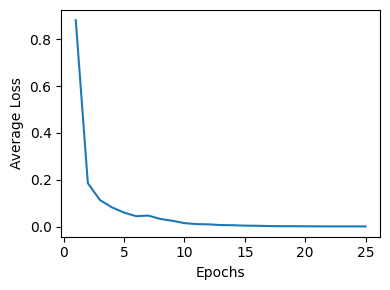

In [ ]:
plt.figure(figsize=(4,3))
plt.xlabel('Epochs')
plt.ylabel('Average Loss')

plt.plot(range(1, len(history)+1), history)
plt.tight_layout()
plt.show()

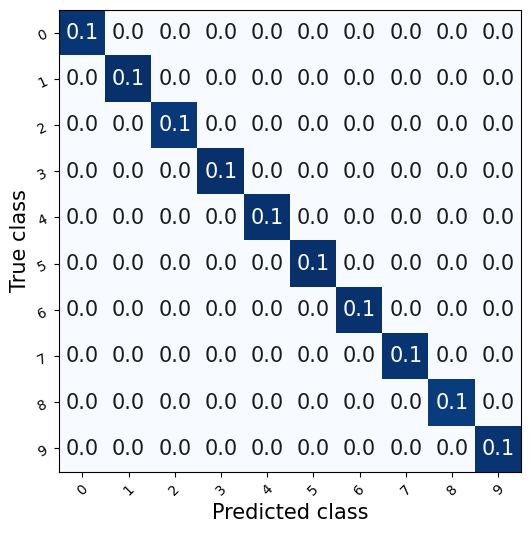

In [ ]:
metric = MulticlassConfusionMatrix(10, normalize='all')
metric.update(model(X), y)
plt.figure(figsize=(6, 6))
metric.plot(ax=plt.gca(), cmap='Blues',)
plt.show()

In [ ]:
df = fetch_california_housing(as_frame=True).frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
X, y = fetch_california_housing(return_X_y=True)
scalar = StandardScaler()
X = scalar.fit_transform(X)
X = torch.FloatTensor(X)
y = torch.FloatTensor(y)
data = TensorDataset(X, y)
loader = DataLoader(data, batch_size=128, shuffle=True, drop_last=False)
loss_fn = nn.MSELoss()
model = Simple_Net(X, y, 0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.009)
epochs = 50
history = model.start_training(X, y, loader, loss_fn, optimizer, epochs)

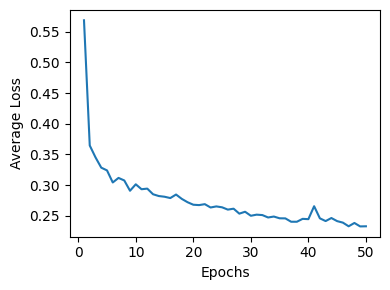

In [ ]:
plt.figure(figsize=(4,3))
plt.xlabel('Epochs')
plt.ylabel('Average Loss')

plt.plot(range(1, len(history)+1), history)
plt.tight_layout()
plt.show()

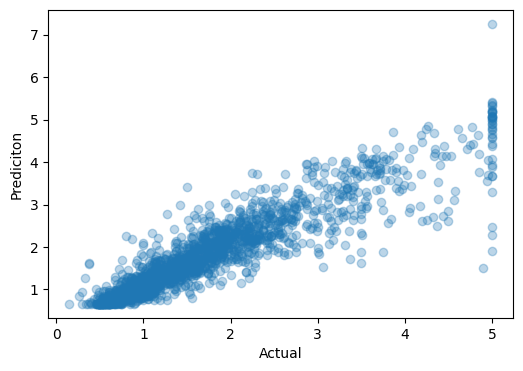

In [ ]:
plt.figure(figsize=(6,4))
plt.xlabel('Actual')
plt.ylabel('Prediciton')
plt.scatter(y[0: 5000: 3], model(X[0: 5000: 3]).detach().numpy(), alpha=0.3)
plt.show()


In [ ]:
torch.sqrt(loss_fn(model(X), y.unsqueeze(1)))

tensor(0.4714, grad_fn=<SqrtBackward0>)

In [ ]:
r2_score(y.detach().numpy(), model(X).detach().numpy())

0.8331412076950073

In [ ]:
metric = torchmetrics.regression.R2Score()
metric.update(model(X), y.unsqueeze(1))
metric.compute()

tensor(0.8331)

In [ ]:
a = torch.tensor(np.arange(4).reshape(2, 2))
b = torch.tensor(np.arange(4, 8).reshape(2, 2))
torch.cat([a, b], dim=0)

tensor([[0, 1],
        [2, 3],
        [4, 5],
        [6, 7]])

In [ ]:
class Wide_Deep(nn.Module):
    def __init__ (self, features, output_dimension, enter_type=1):
        super().__init__()
        self.type = enter_type
        self.deep = nn.Sequential(
            nn.Linear(features, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU()
        )
        self.output_layer = nn.Linear(32 + features, output_dimension)

    def forward(self, X):
        deep_output = self.deep(X)
        wide_and_deep = torch.cat([deep_output, X], dim=1)
        return self.output_layer(wide_and_deep)

    def train_model(self, loader, optimizer, loss_fn, epochs):
        training_loss = []
        for i in range(epochs):
            epoch_loss = 0
            self.train()
            for X, y in loader:
                if self.type == 1:
                    loss = loss_fn(self(X), y)
                else :
                    loss = loss_fn(self(X), y.unsqueeze(1))
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item()
            training_loss.append(epoch_loss/len(loader))
        plt.figure()
        plt.xlabel('Epochs')
        plt.ylabel('Average Loss')
        plt.plot(range(1, len(training_loss)+1), training_loss)
        plt.show()

    def evaluate(self, X, y):
        with torch.inference_mode():
            y_pred = self(X)
        metric = R2Score()
        metric.update(y_pred, y.unsqueeze(1))
        r2_score = metric.compute()
        metric_2 = MeanSquaredError(squared=False)
        metric_2.update(y_pred, y.unsqueeze(1))
        rmse = metric_2.compute()
        return r2_score, rmse

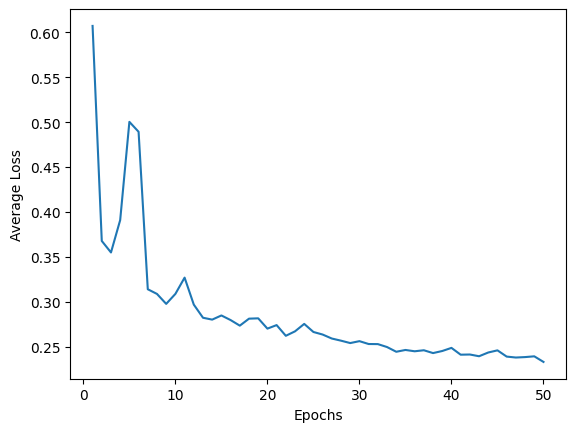

(tensor(0.8295), tensor(0.4765))

In [ ]:
X, y = fetch_california_housing(return_X_y=True)
scalar = StandardScaler()
X = scalar.fit_transform(X)
X = torch.FloatTensor(X)
y = torch.FloatTensor(y)
data = TensorDataset(X, y)
loader = DataLoader(data, batch_size=128, shuffle=True, drop_last=False)
loss_fn = nn.MSELoss()
model = Wide_Deep(X.shape[1], 1, 0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.009)
epochs = 50
model.train_model(loader, optimizer, loss_fn, epochs)
model.evaluate(X, y)

In [ ]:
X.shape

torch.Size([20640, 8])

In [ ]:
class Wide_DeepV2(nn.Module):
    def __init__ (self, features, features_deep, features_wide, output_dimension, enter_type=1):
        super().__init__()
        self.features = features
        self.features_deep = features_deep
        self.features_wide = features_wide
        self.type = enter_type
        self.deep = nn.Sequential(
            nn.Linear(features_deep, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU()
        )
        self.output_layer = nn.Linear(32 + features_wide, output_dimension)

    def forward(self, X):
        X_deep = X[:, :self.features_deep]
        X_wide = X[:, (self.features - self.features_wide):]
        deep_output = self.deep(X_deep)
        wide_and_deep = torch.cat([deep_output, X_wide], dim=1)
        return self.output_layer(wide_and_deep)

    def train_model(self, loader, optimizer, loss_fn, epochs):
        training_loss = []
        for i in range(epochs):
            epoch_loss = 0
            self.train()
            for X, y in loader:
                if self.type == 1:
                    loss = loss_fn(self(X), y)
                else :
                    loss = loss_fn(self(X), y.unsqueeze(1))
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item()
            training_loss.append(epoch_loss/len(loader))
        plt.figure()
        plt.xlabel('Epochs')
        plt.ylabel('Average Loss')
        plt.plot(range(1, len(training_loss)+1), training_loss)
        plt.show()

    def evaluate(self, X, y):
        with torch.inference_mode():
            y_pred = self(X)
        metric = R2Score()
        metric.update(y_pred, y.unsqueeze(1))
        r2_score = metric.compute()
        metric_2 = MeanSquaredError(squared=False)
        metric_2.update(y_pred, y.unsqueeze(1))
        rmse = metric_2.compute()
        return r2_score, rmse

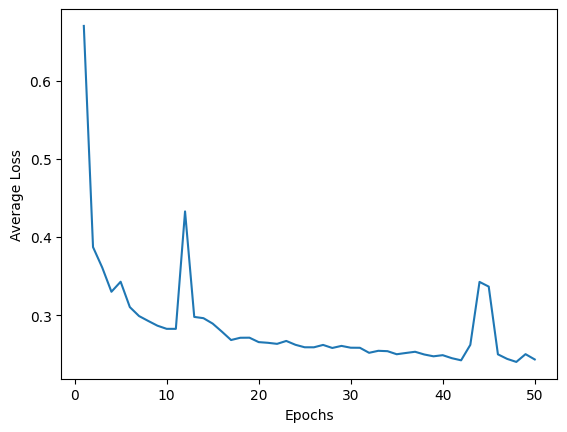

(tensor(0.8187), tensor(0.4913))

In [ ]:
loss_fn = nn.MSELoss()
model = Wide_DeepV2(X.shape[1], 8, 4, 1, 0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.009)
epochs = 50
model.train_model(loader, optimizer, loss_fn, epochs)
model.evaluate(X, y)

In [ ]:
X, y = fetch_california_housing(return_X_y=True)
scalar = StandardScaler()
X = scalar.fit_transform(X)
X = torch.FloatTensor(X)
y = torch.FloatTensor(y)

In [ ]:
dataset = TensorDataset(X[:10, :2], X[:10, 2:4], y[:10])
dataset[0]

(tensor([2.3448, 0.9821]), tensor([ 0.6286, -0.1538]), tensor(4.5260))

In [ ]:
X[0], y[0]

(tensor([ 2.3448,  0.9821,  0.6286, -0.1538, -0.9744, -0.0496,  1.0525, -1.3278]),
 tensor(4.5260))

In [ ]:
loader = DataLoader(dataset, batch_size=2)

for X1, X2, y in loader:
    print('\n \n')
    print(X1)
    print('\n', X2, '\n', y, '\n')


 

tensor([[ 2.3448,  0.9821],
        [ 2.3322, -0.6070]])

 tensor([[ 0.6286, -0.1538],
        [ 0.3270, -0.2633]]) 
 tensor([4.5260, 3.5850]) 


 

tensor([[1.7827, 1.8562],
        [0.9330, 1.8562]])

 tensor([[ 1.1556, -0.0490],
        [ 0.1570, -0.0498]]) 
 tensor([3.5210, 3.4130]) 


 

tensor([[-0.0129,  1.8562],
        [ 0.0874,  1.8562]])

 tensor([[ 0.3447, -0.0329],
        [-0.2697,  0.0147]]) 
 tensor([3.4220, 2.6970]) 


 

tensor([[-0.1114,  1.8562],
        [-0.3951,  1.8562]])

 tensor([[-0.2009, -0.3066],
        [-0.2552, -0.0735]]) 
 tensor([2.9920, 2.4140]) 


 

tensor([[-0.9424,  1.0616],
        [-0.0945,  1.8562]])

 tensor([[-0.4587,  0.0443],
        [-0.1853, -0.2247]]) 
 tensor([2.2670, 2.6110]) 



In [ ]:
for *X_batch , y in loader:
    print(X_batch,'\n')

[tensor([[ 2.3448,  0.9821],
        [ 2.3322, -0.6070]]), tensor([[ 0.6286, -0.1538],
        [ 0.3270, -0.2633]])] 

[tensor([[1.7827, 1.8562],
        [0.9330, 1.8562]]), tensor([[ 1.1556, -0.0490],
        [ 0.1570, -0.0498]])] 

[tensor([[-0.0129,  1.8562],
        [ 0.0874,  1.8562]]), tensor([[ 0.3447, -0.0329],
        [-0.2697,  0.0147]])] 

[tensor([[-0.1114,  1.8562],
        [-0.3951,  1.8562]]), tensor([[-0.2009, -0.3066],
        [-0.2552, -0.0735]])] 

[tensor([[-0.9424,  1.0616],
        [-0.0945,  1.8562]]), tensor([[-0.4587,  0.0443],
        [-0.1853, -0.2247]])] 



In [ ]:
print(X_batch)

[tensor([[-0.9424,  1.0616],
        [-0.0945,  1.8562]]), tensor([[-0.4587,  0.0443],
        [-0.1853, -0.2247]])]


In [ ]:
print(*X_batch)

tensor([[-0.9424,  1.0616],
        [-0.0945,  1.8562]]) tensor([[-0.4587,  0.0443],
        [-0.1853, -0.2247]])


In [ ]:
for *X_batch , y in loader:
    print(*X_batch,'\n')

tensor([[ 2.3448,  0.9821],
        [ 2.3322, -0.6070]]) tensor([[ 0.6286, -0.1538],
        [ 0.3270, -0.2633]]) 

tensor([[1.7827, 1.8562],
        [0.9330, 1.8562]]) tensor([[ 1.1556, -0.0490],
        [ 0.1570, -0.0498]]) 

tensor([[-0.0129,  1.8562],
        [ 0.0874,  1.8562]]) tensor([[ 0.3447, -0.0329],
        [-0.2697,  0.0147]]) 

tensor([[-0.1114,  1.8562],
        [-0.3951,  1.8562]]) tensor([[-0.2009, -0.3066],
        [-0.2552, -0.0735]]) 

tensor([[-0.9424,  1.0616],
        [-0.0945,  1.8562]]) tensor([[-0.4587,  0.0443],
        [-0.1853, -0.2247]]) 



In [ ]:
class Myclass():
    def __init__(self, name, age):
        self.name = name
        self.age = age
        self.dict = {'name': name, 'age': age}
    def __len__(self):
        return len(self.dict)
    def __getitem__(self, key):
        return self.dict[key]

instance = Myclass('qamar', 20)
instance.dict

{'name': 'qamar', 'age': 20}

In [ ]:
len(instance.dict)

2

In [ ]:
len(instance)

2

In [ ]:
instance['age']

20

In [ ]:
instance.dict['age']

20

In [ ]:
X, y = fetch_california_housing(return_X_y=True)
scalar = StandardScaler()
X = scalar.fit_transform(X)
X = torch.FloatTensor(X)
y = torch.FloatTensor(y)

In [ ]:
dataset = TensorDataset(X[:10, :2], X[:10, 2:4], y[:10])
loader = DataLoader(dataset)


In [ ]:
obj =  nn.Module()

In [ ]:
obj = torch.utils.data.Dataset()
obj

In [ ]:
# obj. #A dead class

In [ ]:
class Data(torch.utils.data.Dataset):
    def __init__(self, X1, X2, yo):
        self.X1 = X1
        self.X2 = X2
        self.yo = yo
    def __len__(self):
        return len(self.yo)
    def __getitem__(self, index):
        dictionary = {'X1': self.X1[index], 'X2': self.X2[index]}
        return dictionary, self.yo[index]


In [ ]:
data = Data(X[:10, :2], X[:10, 2:4], y[:6])    #We can pass any mismatch dataset it will be matched by rows when we pass instance in the DataLoader Class

#also we always use __len__ return self.yo because the batches will change their rows count only by yo

In [ ]:
data.X1

tensor([[ 2.3448,  0.9821],
        [ 2.3322, -0.6070],
        [ 1.7827,  1.8562],
        [ 0.9330,  1.8562],
        [-0.0129,  1.8562],
        [ 0.0874,  1.8562],
        [-0.1114,  1.8562],
        [-0.3951,  1.8562],
        [-0.9424,  1.0616],
        [-0.0945,  1.8562]])

In [ ]:
data.X2


tensor([[ 0.6286, -0.1538],
        [ 0.3270, -0.2633],
        [ 1.1556, -0.0490],
        [ 0.1570, -0.0498],
        [ 0.3447, -0.0329],
        [-0.2697,  0.0147],
        [-0.2009, -0.3066],
        [-0.2552, -0.0735],
        [-0.4587,  0.0443],
        [-0.1853, -0.2247]])

In [ ]:
data.yo

tensor([4.5260, 3.5850, 3.5210, 3.4130, 3.4220, 2.6970])

In [ ]:
len(data)

10

In [ ]:
data[0]

({'X1': tensor([2.3448, 0.9821]), 'X2': tensor([ 0.6286, -0.1538])},
 tensor(4.5260))

In [ ]:
data[-1]

({'X1': tensor([-0.0945,  1.8562]), 'X2': tensor([-0.1853, -0.2247])},
 tensor(2.6970))

In [ ]:
loader_2 = DataLoader(data, batch_size=2, shuffle=True)


In [ ]:
len(loader_2)

5

In [ ]:
for d in loader_2:
    print(d,'\n')

IndexError: index 8 is out of bounds for dimension 0 with size 6